# 08. 평균 기준 대비 어긋남

지금까지는 도로타입별·노선별 돌발구분 구성비를 개별적으로 봤다. 이 노트북은 "전국
평균"과 "도로타입 평균"을 기준점으로 잡고, 거기서 얼마나 벗어나는지를 하나의 숫자
(어긋남, %p)로 요약한다.

**목적**: 전국 평균 대비 도로타입별 어긋남(H1 보강), 도로타입 평균 대비 노선별
어긋남(H4 보강)을 계산한다.
**입력 데이터**: `load(with_region=False)`.
**출력물**: `outputs/figures/average_mismatch_by_road_type.png`,
`docs/average_mismatch.md`에 쓸 표.
**다음 노트북**: 없음(마지막 노트북).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
import matplotlib.pyplot as plt
from src.load_data import load
from src.notebook_setup import init_notebook

FIG_DIR = init_notebook()

df = load(with_region=False)
df.shape

(623188, 18)

## 8.1 유형 묶음과 제외 기준

`돌발구분` 원값 6개를 4개 묶음으로 매핑한다.

In [2]:
TYPE_MAP = {
    "공사": "공사",
    "교통사고": "교통사고",
    "기타돌발": "정체·고장 등(기타돌발)",
    "기상": "기타(기상·재난·기타)",
    "재난": "기타(기상·재난·기타)",
    "기타": "기타(기상·재난·기타)",
}
print("돌발구분 원값:", sorted(df["돌발구분"].unique().tolist()))
mapping_table = pd.DataFrame(
    [(k, v) for k, v in TYPE_MAP.items()], columns=["돌발구분(원값)", "유형 묶음"]
)
mapping_table

돌발구분 원값: ['공사', '교통사고', '기상', '기타', '기타돌발', '재난']


,돌발구분(원값),유형 묶음
0,공사,공사
1,교통사고,교통사고
2,기타돌발,정체·고장 등(기타돌발)
3,기상,기타(기상·재난·기타)
4,재난,기타(기상·재난·기타)
5,기타,기타(기상·재난·기타)


In [3]:
df["유형"] = df["돌발구분"].map(TYPE_MAP)
assert df["유형"].isna().sum() == 0, "매핑 안 된 돌발구분 원값이 있다"

is_blank_type = df["도로타입"].isna() | df["도로타입"].astype(str).str.strip().isin(["-", ""])
n_excluded = int(is_blank_type.sum())
n_before = len(df)
df2 = df.loc[~is_blank_type].copy()
n_after = len(df2)
print(f"도로타입 비어있음/- 제외: {n_excluded}건 (전체 {n_before}건 중)")
print(f"분석 대상: {n_after}건")

도로타입 비어있음/- 제외: 860건 (전체 623188건 중)
분석 대상: 622328건


## 8.2 1-1. 전국 평균 vs 도로타입 (H1 연결)

In [4]:
national_pct = df2["유형"].value_counts(normalize=True).mul(100)
national_pct = national_pct.reindex(["공사", "교통사고", "정체·고장 등(기타돌발)", "기타(기상·재난·기타)"])
national_pct

유형
공사               32.266907
교통사고             23.455638
정체·고장 등(기타돌발)    34.163014
기타(기상·재난·기타)     10.114441
Name: proportion, dtype: float64

In [5]:
road_type_pct = (
    pd.crosstab(df2["도로타입"], df2["유형"], normalize="index").mul(100)
    .reindex(columns=["공사", "교통사고", "정체·고장 등(기타돌발)", "기타(기상·재난·기타)"])
)
road_type_count = df2["도로타입"].value_counts()
road_type_pct["건수"] = road_type_count
road_type_pct = road_type_pct.sort_values("건수", ascending=False)
road_type_pct

유형,공사,교통사고,정체·고장 등(기타돌발),기타(기상·재난·기타),건수
도로타입,,,,,
고속국도,25.215914,19.983132,43.419644,11.381310,483758
특별광역시도,56.014764,34.448191,0.000000,9.537045,43892
일반국도,63.852601,25.840066,6.443656,3.863676,39729
도시고속국도,22.722265,75.993728,0.000000,1.284007,23598
시군도,76.412682,17.697946,0.000000,5.889372,23466
지방도,75.110940,19.795485,0.000000,5.093575,5183
국가지원지방도,62.250185,29.718727,0.000000,8.031088,2702


In [6]:
CATS = ["공사", "교통사고", "정체·고장 등(기타돌발)", "기타(기상·재난·기타)"]


def mismatch_vs(row_pct: pd.Series, base_pct: pd.Series) -> float:
    return 0.5 * sum(abs(row_pct[c] - base_pct[c]) for c in CATS)


rows = []
for rt in road_type_pct.index:
    row_pct = road_type_pct.loc[rt, CATS]
    mm = mismatch_vs(row_pct, national_pct)
    diffs = {c: row_pct[c] - national_pct[c] for c in CATS}
    top_cat = max(diffs, key=diffs.get)  # 실제-평균 차이가 가장 큰(가장 초과한) 유형
    rows.append({
        "도로타입": rt, "건수": int(road_type_count[rt]), "어긋남(%p)": round(mm, 1),
        "가장_초과한_유형": top_cat, "초과폭(%p)": round(diffs[top_cat], 1),
    })
mismatch_by_type = pd.DataFrame(rows).sort_values("어긋남(%p)", ascending=False).reset_index(drop=True)
mismatch_by_type

,도로타입,건수,어긋남(%p),가장_초과한_유형,초과폭(%p)
0,도시고속국도,23598,52.5,교통사고,52.5
1,시군도,23466,44.1,공사,44.1
2,지방도,5183,42.8,공사,42.8
3,국가지원지방도,2702,36.2,공사,30.0
4,특별광역시도,43892,34.7,공사,23.7
5,일반국도,39729,34.0,공사,31.6
6,고속국도,483758,10.5,정체·고장 등(기타돌발),9.3


In [7]:
highway_share = road_type_count.get("고속국도", 0) / n_after * 100
print(f"전국 평균 중 고속국도 비중: {highway_share:.1f}% ({road_type_count.get('고속국도', 0):,}건 / {n_after:,}건)")

전국 평균 중 고속국도 비중: 77.7% (483,758건 / 622,328건)


saved /Users/ojaemin/Desktop/취준/프로젝트/도로돌발프로젝트/outputs/figures/average_mismatch_by_road_type.png


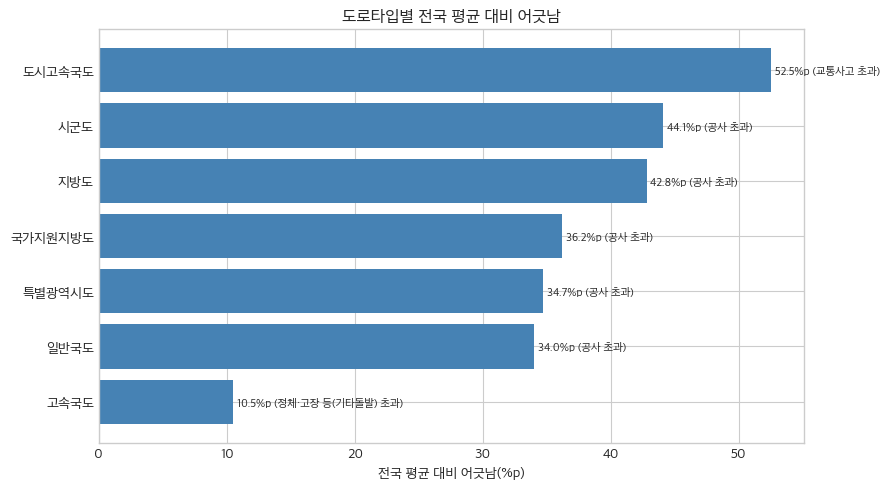

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
order = mismatch_by_type.sort_values("어긋남(%p)", ascending=True)
ax.barh(order["도로타입"], order["어긋남(%p)"], color="steelblue")
ax.set_xlabel("전국 평균 대비 어긋남(%p)")
ax.set_title("도로타입별 전국 평균 대비 어긋남")
for i, (v, cat) in enumerate(zip(order["어긋남(%p)"], order["가장_초과한_유형"])):
    ax.text(v + 0.3, i, f"{v:.1f}%p ({cat} 초과)", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "average_mismatch_by_road_type.png", dpi=150)
print("saved", FIG_DIR / "average_mismatch_by_road_type.png")

## 8.3 1-2. 도로타입 평균 vs 노선 (H4 연결)

In [9]:
ROAD_TYPES_BY_NUMBER = ["고속국도", "국가지원지방도", "도시고속국도", "지방도", "일반국도"]
ROAD_TYPES_BY_NAME = ["특별광역시도", "시군도"]

df2["노선"] = None
num_mask = df2["도로타입"].isin(ROAD_TYPES_BY_NUMBER)
name_mask = df2["도로타입"].isin(ROAD_TYPES_BY_NAME)
n_missing_roadnum = int(df2.loc[num_mask, "도로번호"].isna().sum())
if n_missing_roadnum:
    print(f"도로번호 결측(노선 식별 불가)으로 노선 분석에서 빠지는 행: {n_missing_roadnum}건")
df2.loc[num_mask, "노선"] = df2.loc[num_mask, "도로번호"].astype("Int64").astype(str)
df2.loc[name_mask, "노선"] = df2.loc[name_mask, "도로명"]
df2.loc[df2["노선"].isin(["<NA>", "nan", "None"]), "노선"] = None

route_counts = df2.groupby(["도로타입", "노선"]).size().rename("건수")
target_routes = route_counts[route_counts >= 300].reset_index()
print("대상 노선 수(돌발 300건 이상):", len(target_routes))

도로번호 결측(노선 식별 불가)으로 노선 분석에서 빠지는 행: 7건


대상 노선 수(돌발 300건 이상): 108


In [10]:
route_rows = []
for _, r in target_routes.iterrows():
    rt, route, cnt = r["도로타입"], r["노선"], r["건수"]
    sub_route = df2[(df2["도로타입"] == rt) & (df2["노선"] == route)]
    sub_rest = df2[(df2["도로타입"] == rt) & (df2["노선"] != route)]
    route_pct = sub_route["유형"].value_counts(normalize=True).mul(100).reindex(CATS).fillna(0.0)
    rest_pct = sub_rest["유형"].value_counts(normalize=True).mul(100).reindex(CATS).fillna(0.0)
    mm = mismatch_vs(route_pct, rest_pct)
    diffs = {c: route_pct[c] - rest_pct[c] for c in CATS}
    top_cat = max(diffs, key=lambda c: abs(diffs[c]))
    route_rows.append({
        "도로타입": rt, "노선": route, "건수": int(cnt), "어긋남(%p)": round(mm, 1),
        "가장_다른_유형": top_cat, "노선_비중(%)": round(route_pct[top_cat], 1),
        "타입평균(제외)_비중(%)": round(rest_pct[top_cat], 1),
    })
route_mismatch = pd.DataFrame(route_rows).sort_values("어긋남(%p)", ascending=False).reset_index(drop=True)
route_mismatch.head(20)

,도로타입,노선,건수,어긋남(%p),가장_다른_유형,노선_비중(%),타입평균(제외)_비중(%)
0,특별광역시도,세종대로,547,68.3,기타(기상·재난·기타),77.0,8.7
1,특별광역시도,율곡대로,353,62.9,기타(기상·재난·기타),72.0,9.0
2,고속국도,500,496,60.1,기타(기상·재난·기타),71.4,11.3
3,특별광역시도,남부순환로,657,51.4,교통사고,85.1,33.7
4,일반국도,48,561,48.9,공사,22.1,64.5
5,특별광역시도,삼일대로,333,47.7,공사,8.7,56.4
6,특별광역시도,강남대로,372,46.2,공사,10.2,56.4
7,특별광역시도,반포대로,484,36.8,공사,19.6,56.4
8,고속국도,130,2309,36.4,공사,60.4,25.0
9,특별광역시도,노들대로,377,36.2,교통사고,70.3,34.1


In [11]:
over20 = route_mismatch[route_mismatch["어긋남(%p)"] >= 20.0]
n_over20 = len(over20)
sum_over20 = int(over20["건수"].sum())
share_over20 = sum_over20 / n_after * 100
print(f"어긋남 20%p 이상 노선 수: {n_over20}")
print(f"그 노선들의 돌발 건수 합계: {sum_over20:,}건, 전체({n_after:,}건) 대비 {share_over20:.1f}%")

어긋남 20%p 이상 노선 수: 41
그 노선들의 돌발 건수 합계: 37,019건, 전체(622,328건) 대비 5.9%


In [12]:
top10 = route_mismatch.head(10)
top10

,도로타입,노선,건수,어긋남(%p),가장_다른_유형,노선_비중(%),타입평균(제외)_비중(%)
0,특별광역시도,세종대로,547,68.3,기타(기상·재난·기타),77.0,8.7
1,특별광역시도,율곡대로,353,62.9,기타(기상·재난·기타),72.0,9.0
2,고속국도,500,496,60.1,기타(기상·재난·기타),71.4,11.3
3,특별광역시도,남부순환로,657,51.4,교통사고,85.1,33.7
4,일반국도,48,561,48.9,공사,22.1,64.5
5,특별광역시도,삼일대로,333,47.7,공사,8.7,56.4
6,특별광역시도,강남대로,372,46.2,공사,10.2,56.4
7,특별광역시도,반포대로,484,36.8,공사,19.6,56.4
8,고속국도,130,2309,36.4,공사,60.4,25.0
9,특별광역시도,노들대로,377,36.2,교통사고,70.3,34.1


## 8.4 112번·1020번(기존 README 예시 노선)

두 노선 모두 돌발 300건 미만이라 8.3절의 "대상 노선"(300건 이상) 집합에는 들지
않는다. 다만 기존 README가 예시로 든 노선이라, 같은 공식으로 어긋남 값만 별도 계산한다
(300건 기준과 무관하게 같은 방식으로 구할 수 있는 값이다).

In [13]:
special_rows = []
for route_id, rt_hint in [("112", "도시고속국도"), ("1020", "지방도")]:
    sub_route = df2[(df2["노선"] == route_id) & (df2["도로타입"] == rt_hint)]
    sub_rest = df2[(df2["노선"] != route_id) & (df2["도로타입"] == rt_hint)]
    cnt = len(sub_route)
    route_pct = sub_route["유형"].value_counts(normalize=True).mul(100).reindex(CATS).fillna(0.0)
    rest_pct = sub_rest["유형"].value_counts(normalize=True).mul(100).reindex(CATS).fillna(0.0)
    mm = mismatch_vs(route_pct, rest_pct)
    diffs = {c: route_pct[c] - rest_pct[c] for c in CATS}
    top_cat = max(diffs, key=lambda c: abs(diffs[c]))
    special_rows.append({
        "노선": route_id, "도로타입": rt_hint, "건수": cnt, "어긋남(%p)": round(mm, 1),
        "가장_다른_유형": top_cat, "노선_비중(%)": round(route_pct[top_cat], 1),
        "타입평균(제외)_비중(%)": round(rest_pct[top_cat], 1),
        "300건_기준_충족": cnt >= 300,
    })
special_df = pd.DataFrame(special_rows)
special_df

,노선,도로타입,건수,어긋남(%p),가장_다른_유형,노선_비중(%),타입평균(제외)_비중(%),300건_기준_충족
0,112,도시고속국도,74,66.7,교통사고,9.5,76.2,False
1,1020,지방도,45,54.0,교통사고,73.3,19.3,False
